# Lab 3: Keras

## Exercise 3.1: German Credit Numeric example in Keras

### Sequential model

In [1]:
import keras
from keras import layers

import tensorflow_datasets as tfds
import tensorflow as tf

# Cargamos el conjunto de datos
ds = tfds.load('german_credit_numeric', split='train',as_supervised=True)

tamano_lote = 1000

elems = ds.batch(tamano_lote)
lote_entrenamiento = None
for elem in elems:
    lote_entrenamiento = elem
    break

I0000 00:00:1793807860.926384  509533 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793807866.125024  509533 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4045 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060, pci bus id: 0000:08:00.0, compute capability: 7.5
I0000 00:00:1793807866.450685  509636 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608


In [ ]:
#TODO - indicar la función de perdida y el algoritmo de optimización
fn_perdida = "binary_crossentropy"
optimizador = "adam"

#Definimos la métrica Precision 
metrica = tf.keras.metrics.Precision()

In [ ]:
tamano_entrada = 24
h0_size = 5
h1_size = 3

model =  keras.Sequential(name="german_credit_sequential")

model.add( tf.keras.layers.InputLayer((tamano_entrada,)))
model.add(layers.Dense(h0_size, activation="sigmoid"))
model.add(layers.Dense(h1_size, activation="sigmoid"))
model.add(layers.Dense(1, activation="sigmoid"))

#Se construye el modelo y se muestra
model.build()
print(model.summary())

Model: "german_credit_sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 5)              │           125 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 147 (588.00 B)

 Trainable params: 147 (588.00 B)

 Non-trainable params: 0 (0.00 B)

None


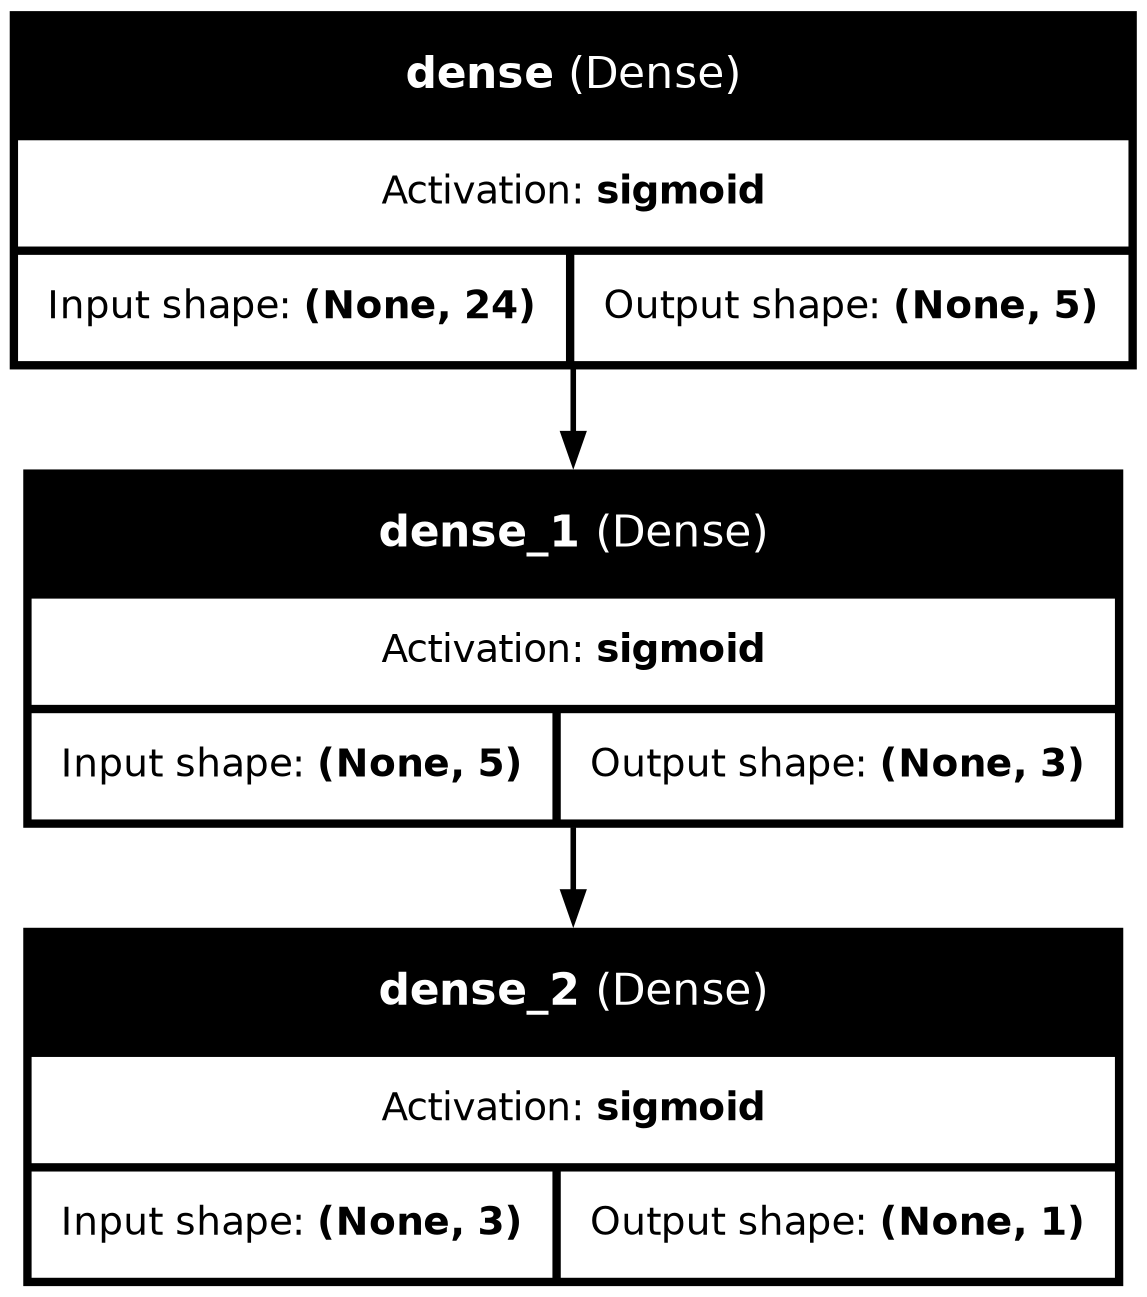

In [4]:
tf.keras.utils.plot_model(model, 'my_first_model.png', show_shapes=True, show_layer_names=True, show_layer_activations=True)

In [5]:
#TODO - indicar los parametros del método compile
model.compile(loss=fn_perdida,
              optimizer=optimizador,
              metrics=[metrica])

In [ ]:
num_epochs =  50
history = model.fit(lote_entrenamiento[0], lote_entrenamiento[1], epochs=num_epochs, batch_size=32)
history.history

Epoch 1/50



 1/32 ━━━━━━━━━━━━━━━━━━━━ 21s 694ms/step - loss: 0.6758 - precision: 0.7812


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6720 - precision: 0.7000   


Epoch 2/50



 1/32 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.6422 - precision: 0.8125


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6527 - precision: 0.7000 


... (141 outputs left out)

Epoch 50/50



 1/32 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.5699 - precision: 0.6774


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5437 - precision: 0.7096 


{'loss': [0.6720245480537415,
  0.6527215838432312,
  0.6390015482902527,
  0.6257115602493286,
  0.6154805421829224,
  0.6118678450584412,
  0.6094509363174438,
  0.6045767664909363,
  0.601645290851593,
  0.5999759435653687,
  0.5986989736557007,
  0.5975126028060913,
  0.5964977741241455,
  0.5957638025283813,
  0.595016598701477,
  0.59377521276474,
  0.592776358127594,
  0.5919233560562134,
  0.5915470123291016,
  0.5906282067298889,
  0.5892853140830994,
  0.5878924131393433,
  0.5868341326713562,
  0.5858376026153564,
  0.5848963260650635,
  0.5839601755142212,
  0.5824016332626343,
  0.5809913873672485,
  0.5797334909439087,
  0.5781883001327515,
  0.5770508646965027,
  0.5753560662269592,
  0.57394939661026,
  0.5723613500595093,
  0.5709260106086731,
  0.5692924857139587,
  0.5680662393569946,
  0.5660625696182251,
  0.5644239187240601,
  0.5626585483551025,
  0.560419499874115,
  0.5604468584060669,
  0.5567683577537537,
  0.554933488368988,
  0.553177535533905,
  0.55165189

In [7]:
#TODO - llamar a evaluate, guardando el resultado
result = model.evaluate(lote_entrenamiento[0], lote_entrenamiento[1])


 1/32 ━━━━━━━━━━━━━━━━━━━━ 3s 104ms/step - loss: 0.5444 - precision: 0.6562


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5412 - precision: 0.7070  


In [8]:
# Mostramos el resultado obtenido
print(model.metrics_names)
print(result)

['loss', 'compile_metrics']
[0.5412440299987793, 0.7070193290710449]


### Functional model

In [9]:
inputs = keras.Input(shape=(24,))
inputs.shape

(None, 24)

In [ ]:
h0_size = 5
h1_size = 3
x = layers.Dense(h0_size, activation='sigmoid')(inputs)
x = layers.Dense(h1_size, activation="sigmoid")(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

In [ ]:
model = keras.Model(inputs=inputs, outputs=outputs, name="german_credit_functional")

print(model.summary())

Model: "german_credit_functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           125 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 147 (588.00 B)

 Trainable params: 147 (588.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=[tf.keras.metrics.Precision()])

num_epochs =  50

history = model.fit(lote_entrenamiento[0], lote_entrenamiento[1], epochs=num_epochs, batch_size=32)

Epoch 1/50



 1/32 ━━━━━━━━━━━━━━━━━━━━ 19s 642ms/step - loss: 0.6032 - precision_1: 0.7188


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6131 - precision_1: 0.7000   


Epoch 2/50



 1/32 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.6417 - precision_1: 0.6562


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6105 - precision_1: 0.7000 

... (141 outputs left out)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5286 - precision_1: 0.7000 


Epoch 50/50



 1/32 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.6056 - precision_1: 0.6250


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5265 - precision_1: 0.7000 


In [13]:
history.history

{'loss': [0.6130922436714172,
  0.6105241775512695,
  0.6091892719268799,
  0.6083229184150696,
  0.607624888420105,
  0.6069273948669434,
  0.6063627004623413,
  0.6056032776832581,
  0.6049938201904297,
  0.6041582226753235,
  0.6034009456634521,
  0.6025115847587585,
  0.6019130945205688,
  0.6008647680282593,
  0.5993872880935669,
  0.5972893834114075,
  0.5953547954559326,
  0.594009280204773,
  0.5912509560585022,
  0.5894404053688049,
  0.5877092480659485,
  0.5858458876609802,
  0.5846989154815674,
  0.5830144882202148,
  0.5807065367698669,
  0.5789640545845032,
  0.5766842365264893,
  0.5746528506278992,
  0.5725398659706116,
  0.5705381631851196,
  0.5685046315193176,
  0.5660401582717896,
  0.5637879371643066,
  0.5615975856781006,
  0.5592057108879089,
  0.5571168661117554,
  0.5542224049568176,
  0.5517111420631409,
  0.5496008396148682,
  0.5473605394363403,
  0.5451244115829468,
  0.5428788661956787,
  0.5398263335227966,
  0.5383506417274475,
  0.5357218384742737,
  0.

In [14]:
#TODO - evaluar el modelo
result = model.evaluate(lote_entrenamiento[0], lote_entrenamiento[1])
print(model.metrics_names)
print(result)


 1/32 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - loss: 0.5132 - precision_1: 0.6562


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5246 - precision_1: 0.7000  


['loss', 'compile_metrics']
[0.5246356725692749, 0.699999988079071]


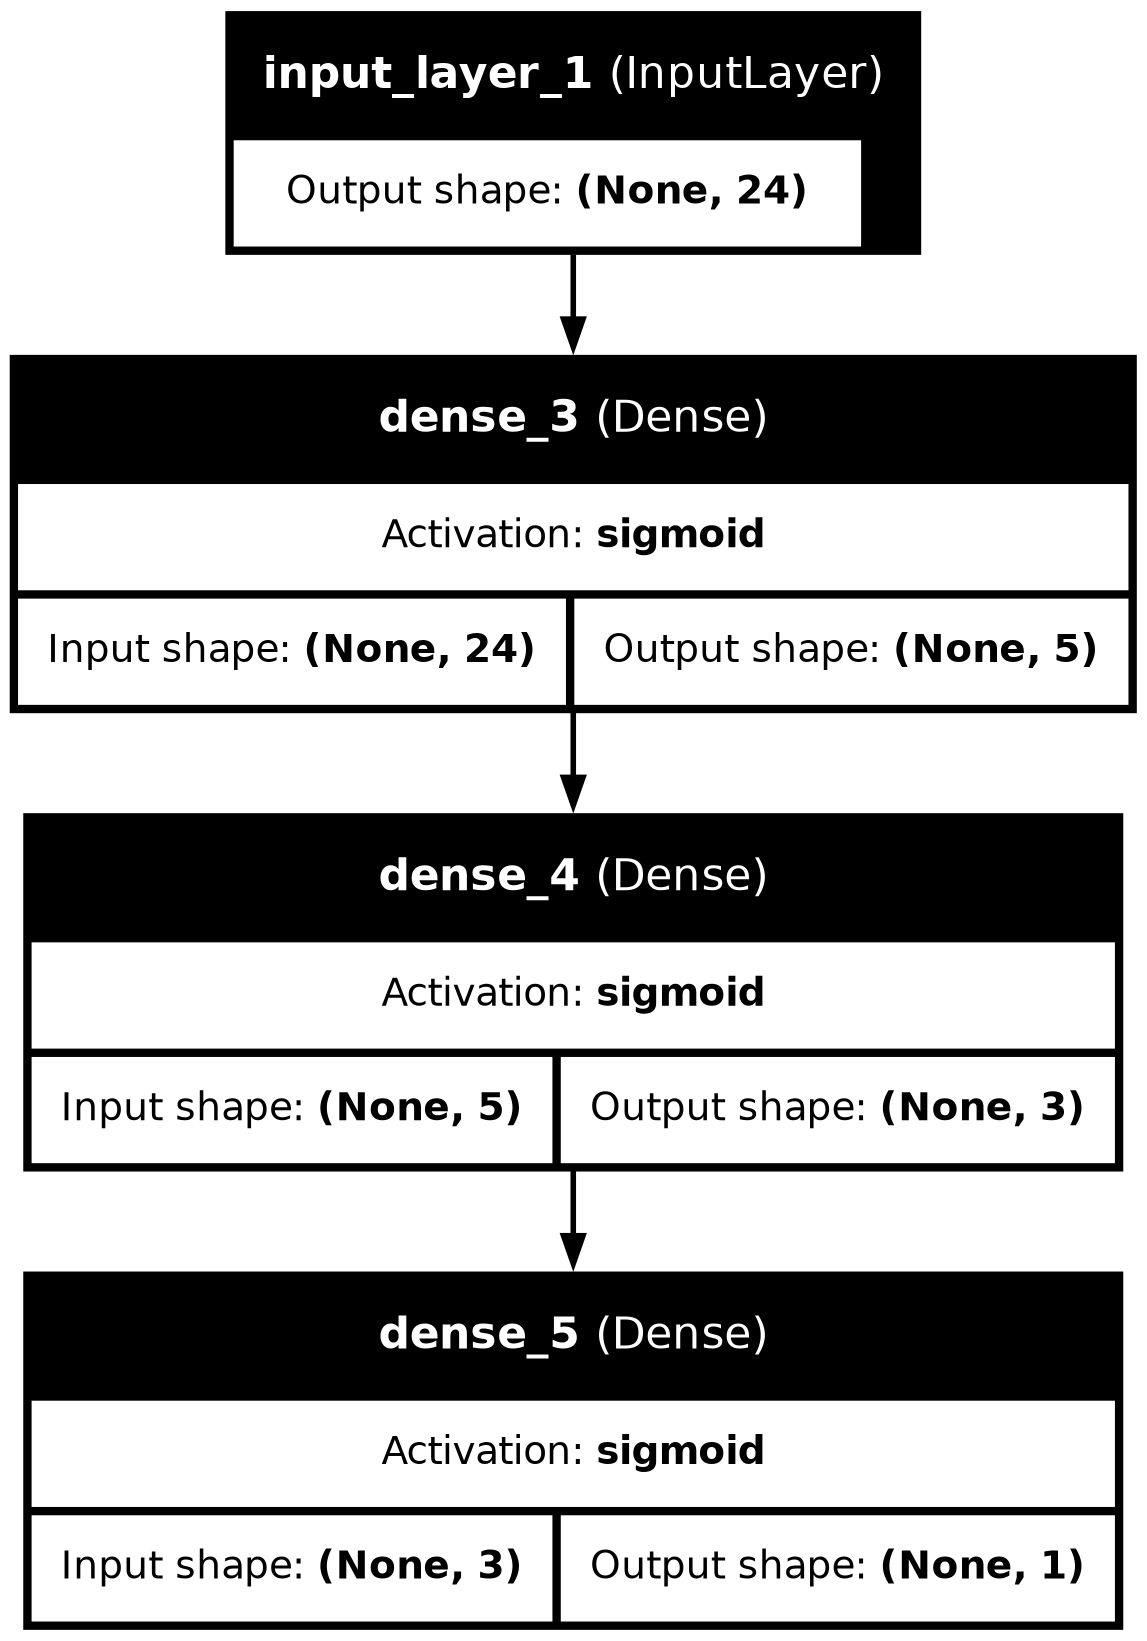

In [15]:
#TODO: muestra el gráfico del modelo
tf.keras.utils.plot_model(model, 'functional_model.png', show_shapes=True, show_layer_names=True, show_layer_activations=True)